# Part 1b — Early-Warning Rules (Association Rule Mining)
**Beyond Credit Scores: Discovering Borrower Risk Profiles and Early Warning Patterns for Loan Default**
DSAI 4102 Applied Data Mining · Group 1 · Jamal Ejaz (60301792)

This notebook looks for **combinations of borrower traits that go with default far more often than average**:
rules of the form *{trait A, trait B} → default*. A lender can check a rule like this on the day of the
application, without a model, which makes it an early-warning signal.

Every rule is tested two ways before I trust it:
- **On later years.** Rules are found on loans issued up to 2013 and re-measured on 2014–2015 loans.
- **Against chance.** The default labels are shuffled to see how many rules appear by luck alone.

**Outputs**
- `data/processed/early_warning_rules.csv`: the final rules
- `figures/01b_*.png`: the figures

## 0. Setup

In [1]:
from pathlib import Path
import json
import time
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import fpgrowth, apriori

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Every value I might have to justify is set here.
# a rule must cover at least 1% of loans - rarer than that and a lender can't act on it
MIN_SUPPORT = 0.01
# at most 3 traits per rule: longer rules get very specific and hard to use
MAX_ITEMS = 3
# a rule must show at least 1.3x the average default rate to count as a warning
MIN_LIFT = 1.3
# a longer rule must beat each shorter rule it contains by at least 0.1 lift
MIN_IMPROVEMENT = 0.10
# find rules on loans issued up to 2013, test them on 2014-2015
TRAIN_LAST_YEAR = 2013
# how many times to shuffle the labels for the chance check
N_SHUFFLES = 20
RANDOM_STATE = 42

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")


fs = json.loads((DATA_DIR / "feature_sets.json").read_text())
df = pd.read_parquet(DATA_DIR / fs["data_file"])
print(f"{len(df):,} loans loaded")

673,314 loans loaded


## 1. Split by time

In [2]:
# I find the rules on older loans and test them on newer ones. That's how a lender would use them:
# learn from the past, apply to the next applicants. A random split would mix years and hide whether
# a rule still works later on.
train = df[df["issue_year"] <= TRAIN_LAST_YEAR].copy()
test = df[df["issue_year"] > TRAIN_LAST_YEAR].copy()

base_train, base_test = train["default"].mean(), test["default"].mean()
print(
    f"Train (issued <= {TRAIN_LAST_YEAR}): {len(train):,} loans, default rate {base_train:.1%}"
)
print(f"Test  (issued 2014-2015):  {len(test):,} loans, default rate {base_test:.1%}")
# Lift is always measured against the base rate of the same period (15.5% vs 14.5%), so the slightly
# different base rates don't distort the comparison.

Train (issued <= 2013): 227,957 loans, default rate 15.5%
Test  (issued 2014-2015):  445,357 loans, default rate 14.5%


## 2. Turn each loan into a set of traits
Association rules work on yes/no items, so every borrower becomes a "basket" of traits.

In [3]:
# Cut points come from the TRAIN loans only, so nothing about the test years leaks into the rules.
# "Top 25%" / "bottom 25%" keeps every cut point objective instead of me picking numbers by hand.
def top_quarter(col):
    return train[col].quantile(0.75)


def bottom_quarter(col):
    return train[col].quantile(0.25)


CUTS = {
    "high_dti": ("dti", ">", top_quarter("dti")),
    "high_utilisation": ("revol_util", ">", top_quarter("revol_util")),
    "high_loan_to_income": ("loan_to_income", ">", top_quarter("loan_to_income")),
    "many_new_accounts": (
        "acc_open_past_24mths",
        ">",
        top_quarter("acc_open_past_24mths"),
    ),
    "low_income": ("annual_inc", "<", bottom_quarter("annual_inc")),
    "short_credit_history": (
        "credit_history_years",
        "<",
        bottom_quarter("credit_history_years"),
    ),
    # 2+ credit checks in 6 months
    "2plus_recent_inquiries": ("inq_last_6mths", ">=", 2),
    # a year or less in the current job
    "short_employment": ("emp_length", "<=", 1),
    "no_mortgage": ("mort_acc", "==", 0),
}
pd.DataFrame(CUTS, index=["feature", "rule", "cut point"]).T

,feature,rule,cut point
high_dti,dti,>,21.83
high_utilisation,revol_util,>,76.0
high_loan_to_income,loan_to_income,>,0.291667
many_new_accounts,acc_open_past_24mths,>,5.0
low_income,annual_inc,<,45000.0
short_credit_history,credit_history_years,<,10.502396
2plus_recent_inquiries,inq_last_6mths,>=,2
short_employment,emp_length,<=,1
no_mortgage,mort_acc,==,0


In [4]:
def make_baskets(data):
    ops = {
        ">": np.greater,
        "<": np.less,
        ">=": np.greater_equal,
        "<=": np.less_equal,
        "==": np.equal,
    }
    items = pd.DataFrame(index=data.index)
    for name, (col, op, cut) in CUTS.items():
        items[name] = ops[op](data[col], cut)
    items["delinquency_on_record"] = data["has_delinq_history"] == 1
    items["public_record"] = data["has_public_record"] == 1
    items["renter"] = data["home_ownership"] == "RENT"
    items["income_verified"] = data["verification_status"] == "Verified"
    for p in data["purpose"].unique():
        items[f"purpose_{p}"] = data["purpose"] == p
    return items.astype(bool)


# Deliberately left out:
# - grade, interest rate and FICO: a rule like "grade E -> default" just repeats Lending Club's own score.
#   I want warnings that come from the borrower's situation.
# - loan term: in our matured cohort 60-month loans stop at 2013 (one issued in 2014 hadn't finished by
#   Dec 2018), so any rule using it could never be tested on later years. I tried it, and those untestable
#   rules crowded the top of the list, so I took it out.
items_train = make_baskets(train)
items_test = make_baskets(test)[items_train.columns]
print(len(items_train.columns), "traits")
items_train.mean().sort_values(ascending=False).round(3).to_frame(
    "share of train loans"
)

21 traits


,share of train loans
purpose_debt_consolidation,0.571
income_verified,0.440
delinquency_on_record,0.415
renter,0.415
no_mortgage,0.320
high_dti,0.250
high_loan_to_income,0.250
high_utilisation,0.250
short_credit_history,0.249
low_income,0.246


## 3. Find the frequent trait combinations (FP-Growth)

In [5]:
# Step 1 of rule mining: find every combination of up to 3 traits that covers at least 1% of loans.
# FP-Growth does this by compressing all baskets into one tree and reading combinations off it,
# so it scans the data only twice. Apriori finds the same combinations by generating candidates
# level by level, scanning the data each time (compared in section 7).
# I mine with a lower support (0.5%) once, so the threshold sweep in section 5 can reuse it.
start = time.perf_counter()
itemsets = fpgrowth(
    items_train, min_support=MIN_SUPPORT / 2, use_colnames=True, max_len=MAX_ITEMS
)
print(
    f"FP-Growth found {len(itemsets):,} frequent combinations in {time.perf_counter() - start:.1f}s"
)

FP-Growth found 619 frequent combinations in 0.6s


In [6]:
# Step 2: turn each combination X into the rule "X -> default".
#   support    = share of loans that have every trait in X (how many borrowers the rule applies to)
#   confidence = default rate among those loans
#   lift       = confidence / base default rate  (2.0 = twice as likely to default as the average loan)
# Lift is the number that matters. Confidence alone misleads when ~15% of all loans default anyway:
# a rule with 18% "confidence" sounds bad but is barely above average.
def score_rules(trait_sets, items, outcome, base_rate):
    # numpy arrays: much faster than looping in pandas
    X, y = items.to_numpy(), np.asarray(outcome)
    position = {name: i for i, name in enumerate(items.columns)}
    rows = []
    for traits in trait_sets:
        # loans that have ALL the traits
        covered = X[:, [position[t] for t in traits]].all(axis=1)
        n = int(covered.sum())
        rate = y[covered].mean() if n else np.nan
        rows.append(
            {
                "traits": frozenset(traits),
                "size": len(traits),
                "loans": n,
                "support": n / len(items),
                "default_rate": rate,
                "lift": rate / base_rate,
            }
        )
    return pd.DataFrame(rows)


rules_all = score_rules(itemsets["itemsets"], items_train, train["default"], base_train)


def readable(traits):
    # frozenset({a, b}) -> "a + b"
    return " + ".join(sorted(traits))


# Preview: the strongest combinations that cover at least 1% of loans
preview = rules_all[rules_all["support"] >= MIN_SUPPORT]
preview = preview.sort_values("lift", ascending=False).head(10)
preview.assign(traits=preview["traits"].map(readable))

,traits,size,loans,support,default_rate,lift
587,high_loan_to_income + many_new_accounts + renter,3,3471,0.015227,0.314031,2.025736
586,high_loan_to_income + many_new_accounts + no_m...,3,3802,0.016679,0.307207,1.981717
585,high_dti + high_loan_to_income + many_new_acco...,3,4844,0.021250,0.304500,1.964259
588,delinquency_on_record + high_loan_to_income + ...,3,3926,0.017223,0.303362,1.956917
590,2plus_recent_inquiries + high_loan_to_income +...,3,2790,0.012239,0.302151,1.949101
584,high_loan_to_income + income_verified + many_n...,3,6775,0.029721,0.298155,1.923327
583,high_loan_to_income + many_new_accounts + purp...,3,6977,0.030607,0.296116,1.910172
589,high_loan_to_income + many_new_accounts + shor...,3,2300,0.010090,0.296087,1.909986
217,2plus_recent_inquiries + high_dti + high_loan_...,3,3877,0.017008,0.294042,1.896793
596,high_loan_to_income + low_income + many_new_ac...,3,2823,0.012384,0.291888,1.882900


## 4. Keep the strong rules and drop the redundant ones

In [7]:
strong = rules_all[
    (rules_all["support"] >= MIN_SUPPORT) & (rules_all["lift"] >= MIN_LIFT)
].copy()

# A longer rule is only worth keeping if the extra trait adds real risk. Example: if {high_dti} already
# has lift 1.4, then {high_dti, renter} at lift 1.45 says nothing new. So a rule must beat EVERY shorter
# rule inside it by at least MIN_IMPROVEMENT, otherwise the shorter one already tells the story.
lift_of = dict(zip(rules_all["traits"], rules_all["lift"]))


def adds_information(traits):
    if len(traits) == 1:
        return True
    subsets = [
        frozenset(s) for k in range(1, len(traits)) for s in combinations(traits, k)
    ]
    return all(lift_of[traits] - lift_of.get(s, 0) >= MIN_IMPROVEMENT for s in subsets)


strong["keep"] = strong["traits"].map(adds_information)
rules = (
    strong[strong["keep"]]
    .drop(columns="keep")
    .sort_values("lift", ascending=False)
    .reset_index(drop=True)
)
print(
    f"{len(strong)} rules pass support and lift -> {len(rules)} left after removing redundant ones"
)
# 259 -> 84: the 175 removed were a strong rule with an extra trait bolted on that added no real risk.

259 rules pass support and lift -> 84 left after removing redundant ones


## 5. How the thresholds change the result

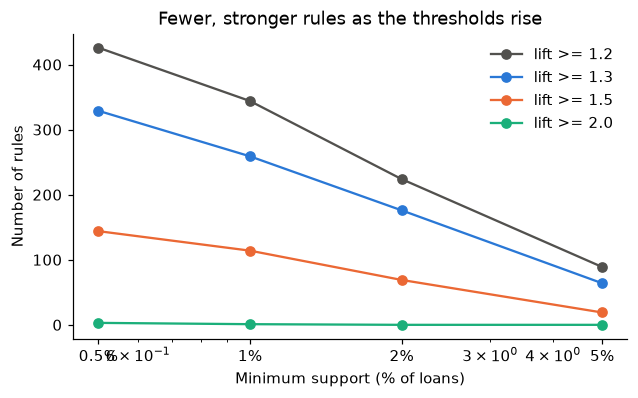

,lift >= 1.2,lift >= 1.3,lift >= 1.5,lift >= 2.0
min support,,,,
0.005,426,329,144,3
0.010,344,259,114,1
0.020,224,176,69,0
0.050,89,64,19,0


In [8]:
# The number of rules depends heavily on the two thresholds, so I show the effect instead of picking blindly.
supports = [0.005, 0.01, 0.02, 0.05]
lifts = [1.2, 1.3, 1.5, 2.0]
sweep = pd.DataFrame(
    {
        f"lift >= {min_lift}": [
            int(((rules_all["support"] >= s) & (rules_all["lift"] >= min_lift)).sum())
            for s in supports
        ]
        for min_lift in lifts
    },
    index=pd.Index(supports, name="min support"),
)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for col, colour in zip(sweep.columns, [GREY, BLUE, ORANGE, "#1baf7a"]):
    ax.plot(sweep.index * 100, sweep[col], marker="o", color=colour, label=col)
ax.set(
    title="Fewer, stronger rules as the thresholds rise",
    xlabel="Minimum support (% of loans)",
    ylabel="Number of rules",
    xscale="log",
)
ax.set_xticks(sweep.index * 100, [f"{s * 100:g}%" for s in supports])
ax.legend(frameon=False)
save(fig, "01b_rule_count_vs_support.png")
plt.show()
# At my settings (1% support, lift 1.3) there are 259 rules. Asking for lift 2.0 leaves just 1, far too
# strict to be useful; raising support to 5% keeps 64 broad, weaker ones. 1% / 1.3 keeps rules that cover
# a meaningful slice of applicants and still mark a clear jump in risk.
sweep

## 6. Is it real? Two checks
### 6.1 Do the rules hold on later years?

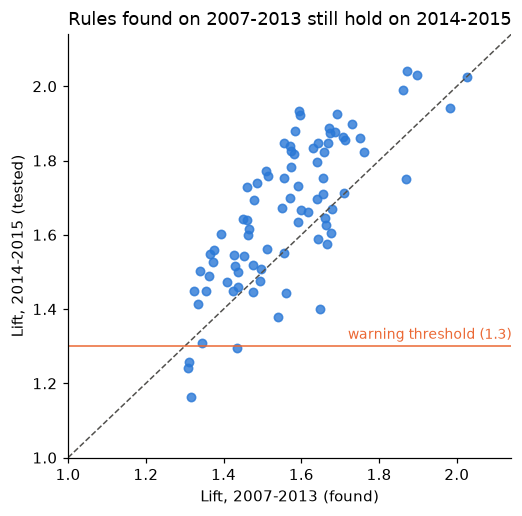

80 of 84 rules still clear lift 1.3 on 2014-2015


In [9]:
# Re-measure every rule on 2014-2015 loans it has never seen, against the 2014-2015 base rate.
test_scores = score_rules(rules["traits"], items_test, test["default"], base_test)
rules["test_support"] = test_scores["support"].values
rules["test_default_rate"] = test_scores["default_rate"].values
rules["test_lift"] = test_scores["lift"].values
rules["holds_out_of_time"] = rules["test_lift"] >= MIN_LIFT

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(rules["lift"], rules["test_lift"], s=30, color=BLUE, alpha=0.8)
lims = [1, max(rules["lift"].max(), rules["test_lift"].max()) + 0.1]
ax.plot(lims, lims, color=GREY, linestyle="--", linewidth=1)
ax.axhline(MIN_LIFT, color=ORANGE, linewidth=1)
ax.text(
    lims[1],
    MIN_LIFT + 0.02,
    f"warning threshold ({MIN_LIFT})",
    color=ORANGE,
    ha="right",
    fontsize=9,
)
ax.set(
    title="Rules found on 2007-2013 still hold on 2014-2015",
    xlabel="Lift, 2007-2013 (found)",
    ylabel="Lift, 2014-2015 (tested)",
    xlim=lims,
    ylim=lims,
)
save(fig, "01b_rules_train_vs_test_lift.png")
plt.show()
print(
    f"{rules['holds_out_of_time'].sum()} of {len(rules)} rules still clear lift {MIN_LIFT} on 2014-2015"
)
# 80 of 84 rules hold. Most points sit ABOVE the dashed line: the rules were even stronger on 2014-2015
# than in the years they were found in. 3 of the 4 that fail were barely over the threshold to begin with.

### 6.2 Could rules this strong appear by chance?

In [10]:
# I shuffle the default labels, which breaks any real link between traits and default, and re-score the
# same trait combinations. Any rule that still clears the thresholds is pure luck. If real rules are
# genuine, the shuffled data should produce close to none.
rng = np.random.default_rng(RANDOM_STATE)
eligible = rules_all[rules_all["support"] >= MIN_SUPPORT]
chance_counts = []
for _ in range(N_SHUFFLES):
    shuffled = pd.Series(rng.permutation(train["default"].values), index=train.index)
    s = score_rules(eligible["traits"], items_train, shuffled, base_train)
    chance_counts.append(int((s["lift"] >= MIN_LIFT).sum()))

print(f"Real data: {len(strong)} rules with lift >= {MIN_LIFT}")
print(
    f"Shuffled labels ({N_SHUFFLES} runs): {np.mean(chance_counts):.1f} on average, at most {max(chance_counts)}"
)
# Zero in every shuffled run, against 259 on the real labels. With ~228k loans, a 1.3x jump in default
# across 1%+ of them doesn't happen by luck.

Real data: 259 rules with lift >= 1.3
Shuffled labels (20 runs): 0.0 on average, at most 0


## 7. FP-Growth vs Apriori

In [11]:
# Both algorithms return exactly the same combinations, so the only difference is speed.
# In theory FP-Growth scales better: it scans the data twice, while Apriori rescans it for every rule
# length. With only 21 traits and at most 3 per rule there are few candidates, so Apriori can keep up
# here - the timings show how each grows as the data doubles.
timings = []
for share in [0.25, 0.5, 1.0]:
    sample = items_train.sample(frac=share, random_state=RANDOM_STATE)
    for name, algo in [("FP-Growth", fpgrowth), ("Apriori", apriori)]:
        start = time.perf_counter()
        found = algo(
            sample, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_ITEMS
        )
        timings.append(
            {
                "algorithm": name,
                "loans": len(sample),
                "seconds": time.perf_counter() - start,
                "combinations": len(found),
            }
        )
timings = pd.DataFrame(timings)
timings.pivot(
    index="loans", columns="algorithm", values=["seconds", "combinations"]
).round(2)
# Both find the same number of combinations at every size, so the only difference is speed.
# Apriori is faster at every size here, and both finish well under a second. But compare how each
# grows from 57k to 228k loans: FP-Growth's time grows more slowly, so with more traits or more data
# it would likely overtake Apriori. (Exact seconds vary slightly between runs.)

seconds           combinations          
algorithm Apriori FP-Growth      Apriori FP-Growth
loans                                             
56989        0.08      0.23        498.0     498.0
113978       0.15      0.37        494.0     494.0
227957       0.31      0.63        494.0     494.0

## 8. Beyond the credit score: does a rule add risk on top of grade?

In [12]:
# A rule could look strong just because it picks out low-grade loans. To check, I compare each rule's
# actual defaults with the defaults its loans' GRADES alone would predict:
#   expected = sum over the rule's loans of (default rate of that loan's grade)
#   lift beyond grade = actual defaults / expected defaults
# 1.0 means grade already explains the rule completely; above 1.0 means the rule finds extra risk.
grade_rate = test.groupby("grade")["default"].mean()
expected_by_grade = test["grade"].map(grade_rate)


def lift_beyond_grade(traits):
    covered = items_test[list(traits)].all(axis=1)
    return test.loc[covered, "default"].sum() / expected_by_grade[covered].sum()


rules["lift_beyond_grade"] = rules["traits"].map(lift_beyond_grade)
top10 = rules[["traits", "test_lift", "lift_beyond_grade"]].head(10)
top10.assign(traits=top10["traits"].map(readable))
# The top rules carry roughly 1.3-1.5x the defaults their grades predict, so they find risk that
# Lending Club's own grade misses.

,traits,test_lift,lift_beyond_grade
0,high_loan_to_income + many_new_accounts + renter,2.025243,1.473324
1,high_loan_to_income + many_new_accounts + no_m...,1.941743,1.412046
2,2plus_recent_inquiries + high_dti + high_loan_...,2.029727,1.407093
3,2plus_recent_inquiries + high_loan_to_income +...,2.040276,1.396279
4,high_loan_to_income + many_new_accounts,1.750071,1.335665
5,2plus_recent_inquiries + high_loan_to_income +...,1.989358,1.368103
6,2plus_recent_inquiries + high_loan_to_income,1.821799,1.296781
7,high_utilisation + many_new_accounts + renter,1.859755,1.350266
8,high_dti + many_new_accounts + renter,1.898826,1.494176
9,high_dti + many_new_accounts + no_mortgage,1.854545,1.457063


## 9. The early-warning rules

In [13]:
final = (
    rules[rules["holds_out_of_time"]].sort_values("test_lift", ascending=False).copy()
)
final["rule"] = final["traits"].map(readable)

table = pd.DataFrame(
    {
        "rule": final["rule"],
        "traits": final["size"],
        "% of loans (test)": (final["test_support"] * 100).round(1),
        "default rate (test)": (final["test_default_rate"] * 100).round(1),
        "lift (found)": final["lift"].round(2),
        "lift (tested)": final["test_lift"].round(2),
        "lift beyond grade": final["lift_beyond_grade"].round(2),
    }
).reset_index(drop=True)
table.to_csv(DATA_DIR / "early_warning_rules.csv", index=False)
table.head(10)
# The pattern behind almost every top rule: borrowing a lot relative to income (high loan-to-income or
# high DTI) while actively seeking new credit (2+ recent inquiries or many new accounts), usually as a
# renter or without a mortgage. Top rule: 2+ inquiries + high loan-to-income + renter -> 29.5% default,
# 2.04x the average loan and 1.40x what its grades predict. "income_verified" shows up again for the
# same reason as in Part 1: Lending Club verified the applicants it already saw as riskier.

,rule,traits,% of loans (test),default rate (test),lift (found),lift (tested),lift beyond grade
0,2plus_recent_inquiries + high_loan_to_income +...,3,1.0,29.5,1.87,2.04,1.40
1,2plus_recent_inquiries + high_dti + high_loan_...,3,1.1,29.4,1.90,2.03,1.41
2,high_loan_to_income + many_new_accounts + renter,3,2.2,29.3,2.03,2.03,1.47
3,2plus_recent_inquiries + high_loan_to_income +...,3,1.1,28.8,1.86,1.99,1.37
4,high_loan_to_income + many_new_accounts + no_m...,3,2.5,28.1,1.98,1.94,1.41
5,2plus_recent_inquiries + high_dti + no_mortgage,3,2.1,28.0,1.59,1.93,1.41
6,income_verified + low_income + many_new_accounts,3,2.5,27.8,1.69,1.93,1.36
7,2plus_recent_inquiries + high_dti + renter,3,2.1,27.8,1.60,1.92,1.41
8,high_dti + many_new_accounts + renter,3,5.0,27.5,1.73,1.90,1.49
9,2plus_recent_inquiries + income_verified + low...,3,1.3,27.3,1.67,1.89,1.26


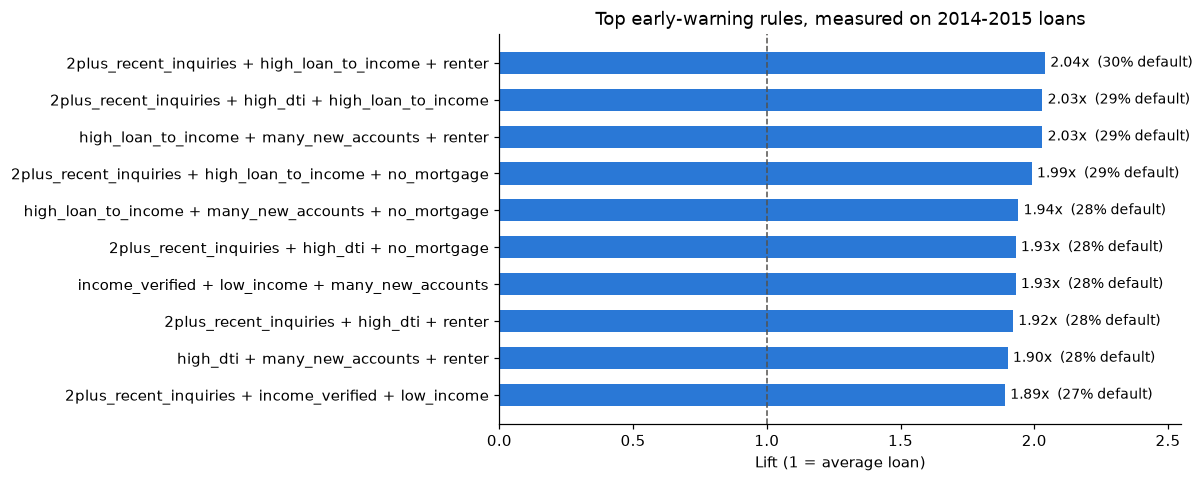

In [14]:
top = table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top["rule"], top["lift (tested)"], color=BLUE, height=0.6)
ax.axvline(1, color=GREY, linestyle="--", linewidth=1)
for y, (lift, rate) in enumerate(zip(top["lift (tested)"], top["default rate (test)"])):
    ax.text(
        lift + 0.02, y, f"{lift:.2f}x  ({rate:.0f}% default)", va="center", fontsize=9
    )
ax.set(
    title="Top early-warning rules, measured on 2014-2015 loans",
    xlabel="Lift (1 = average loan)",
)
ax.set_xlim(0, top["lift (tested)"].max() * 1.25)
save(fig, "01b_top_rules.png")
plt.show()